# EXP-014 — Cân bằng lớp cho Random Forest

**Notebook trình bày và tổng hợp:** [notebooks/experiments/Mai_EXP-014_RF_balancing.ipynb](../../../notebooks/experiments/Mai_EXP-014_RF_balancing.ipynb)

**Người thực hiện:** Mai  
**Ngày lập thực nghiệm:** 21/11/2026  
**So sánh train và test** -22/11/2026  
**Trạng thái:** chuẩn bị thực nghiệm. kết quả được tổng hợp sau khi thực hiện huấn luyện.

Thử thêm `class_weight="balanced"` vào Random Forest đã chỉnh tham số ở EXP-009. Giữ cùng dữ liệu, người test và tham số đã chọn cho từng outer fold ở cả hai phiên bản. Chỉ thay trọng số lớp khi huấn luyện.


## 02 — Câu hỏi nghiên cứu

Cân bằng trọng số lớp có cải thiện Macro-F1, Balanced Accuracy và khả năng nhận diện các lớp ít mẫu so với RF tuning chưa cân bằng không?

Giả thuyết đặt ra là trọng số lớp có thể giúp nhận diện các lớp ít mẫu tốt hơn, nhưng cũng có thể làm giảm điểm ở các lớp còn lại. Xem kết quả riêng cho nhị phân và ba lớp. Theo dõi cả mức thay đổi điểm giữa người tham gia.


In [1]:
from pathlib import Path
import json
import hashlib
import subprocess
from datetime import datetime, timezone, timedelta
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

here = Path.cwd()
repo = next(p for p in (here, *here.parents) if (p / 'src/wesad/evaluation.py').is_file())
experiment = repo / 'experiments/03_balancing/EXP-014_RF'
reference = repo / 'outputs/exp009_rf_mai_20261120'
output = repo / 'outputs/exp014_rf_mai_20261121'
train_python = repo / '.venv-g1/Scripts/python.exe'
tasks = ['binary', 'multiclass']
task_names = {'binary': 'Nhị phân', 'multiclass': 'Ba lớp'}
metrics = ['macro_f1', 'balanced_accuracy']


## 03 — Dữ liệu và đối chứng

Bảng physiological68 gồm 68 đặc trưng sinh lý trên 15 người, được giữ nguyên phiên bản và checksum như EXP-009. Nhị phân: 0 là không stress, 1 là stress. Ba lớp: 1 là baseline, 2 là stress, 3 là amusement. Mã người và mã cửa sổ không được sử dụng làm đặc trưng.

So sánh với RF tuning của EXP-009 trong `outputs/exp009_rf_mai_20261120/`. Dùng tham số chọn bằng inner CV của EXP-009. Không chọn lại theo điểm outer test ở EXP-014.


In [2]:
reference_config = yaml.safe_load((reference / 'config.yaml').read_text(encoding='utf-8'))
reference_summary = json.loads((reference / 'summary.json').read_text(encoding='utf-8'))
assert reference_summary['status'] == 'complete'
data_path = repo / reference_config['features']
assert hashlib.sha256(data_path.read_bytes()).hexdigest() == reference_config['feature_sha256']
schema = json.loads((repo / reference_config['schema']).read_text(encoding='utf-8'))
frame = pd.read_csv(data_path, dtype={'subject_id': str, 'window_id': str})
assert len(schema['feature_columns']) == 68
assert set(frame.subject_id) == set(reference_config['expected_subjects'])
print('Số cửa sổ:', len(frame), '| Số người:', frame.subject_id.nunique(), '| Số đặc trưng: 68')
display(frame.groupby(['subject_id', 'label_original']).size().unstack(fill_value=0))


Số cửa sổ: 6189 | Số người: 15 | Số đặc trưng: 68


label_original,1,2,3
subject_id,,,
S10,226,135,65
S11,227,126,64
S13,226,124,67
S14,219,126,65
S15,226,128,64
S16,226,125,64
S17,226,135,65
S2,219,113,63
S3,218,118,65


## 04 — Phương pháp đánh giá

- LOSO ngoài: 14 người train và 1 người test, đủ 15 fold cho mỗi bài toán.
- Giữ tham số đã chọn bằng 3 inner GroupKFold của EXP-009 cho đúng task và người test. EXP-014 không tìm kiếm tham số mới.
- Median imputation chỉ được fit trên outer train. RF không sử dụng scaling hoặc oversampling.
- Trọng số lớp được RF tính từ nhãn của tập train theo công thức `n_train / (n_classes × n_class)`.
- Seed 42, `n_jobs=1`. chỉ thêm `class_weight="balanced"` so với đối chứng.
- Macro-F1 và Balanced Accuracy được tổng hợp bằng mean và SD mẫu (`ddof=1`) qua 15 người, tách riêng hai bài toán.

Các dự đoán ngoài mẫu được ghép theo bài toán, người và cửa sổ để kiểm tra cùng tập đánh giá. Dùng confusion matrix gộp cửa sổ để xem lỗi. Không dùng kết quả này thay cho điểm trung bình theo người.


## 05 — Cấu hình

Giữ đúng `n_estimators`, `max_depth`, `max_features` theo từng fold của EXP-009. Lưu cấu hình đầy đủ khi chạy notebook. Ghi ngày chạy thực tế, không mặc định lấy ngày lập notebook.


In [3]:
fixed_params = json.loads((reference / 'best_params.json').read_text(encoding='utf-8'))
expected_keys = {f'{task}/rf/{subject}' for task in tasks for subject in reference_config['expected_subjects']}
assert set(fixed_params) == expected_keys
assert all(set(p) == {'model__n_estimators', 'model__max_depth', 'model__max_features'} for p in fixed_params.values())
config = {k: v for k, v in reference_config.items() if k not in {'search_spaces', 'outer_subjects', 'record_mlp_loss'}}
config.update(
    experiment_id='EXP-014', author='Mai',
    run_date=datetime.now(timezone(timedelta(hours=7))).date().isoformat(),
    protocol='exp014_rf_balanced_fixed_exp009_v1', run_kind='balanced_comparison',
    output_dir=str(output.relative_to(repo)), balance=True, nested=False,
    fixed_fold_params=fixed_params,
    reference_params_sha256=hashlib.sha256((reference / 'best_params.json').read_bytes()).hexdigest(),
    source_paths=['src/wesad/data.py', 'src/wesad/evaluation.py', 'src/wesad/models.py', 'src/wesad/utils.py'],
)
display(pd.DataFrame([{'fold': k, **v} for k, v in fixed_params.items()]))
print('class_weight = balanced; không tìm kiếm lại tham số.')


,fold,model__max_depth,model__max_features,model__n_estimators
0,multiclass/rf/S10,NaN,sqrt,200
1,multiclass/rf/S11,NaN,sqrt,200
2,multiclass/rf/S13,NaN,sqrt,200
3,multiclass/rf/S14,10.0,sqrt,100
4,multiclass/rf/S15,NaN,sqrt,200
5,multiclass/rf/S16,NaN,sqrt,200
6,multiclass/rf/S17,NaN,sqrt,200
7,multiclass/rf/S2,NaN,sqrt,200
8,multiclass/rf/S3,10.0,sqrt,100
9,multiclass/rf/S4,NaN,sqrt,200


class_weight = balanced; không tìm kiếm lại tham số.


## 06 — Huấn luyện

Huấn luyện bằng `run_experiment` trong mã dùng chung. `RUN_TRAIN=True` thực hiện chạy hoặc tiếp tục các fold chưa hoàn thành. `False` chỉ đọc kết quả đã có. Checkpoint chỉ được dùng lại khi cấu hình, dữ liệu, mã nguồn và môi trường còn khớp chữ ký.

Khi cấu hình hoặc ngày chạy thay đổi so với checkpoint cũ, sử dụng một đường dẫn `output` mới ở phần đầu trước khi thực hiện huấn luyện. Các bảng kết quả và hình của EXP-014 được lưu trong thư mục thực nghiệm. các file chi tiết nằm tại `outputs/`.


In [4]:
RUN_TRAIN = False
experiment.mkdir(parents=True, exist_ok=True)
config_path = experiment / 'config.yaml'
config_path.write_text(yaml.safe_dump(config, sort_keys=False, allow_unicode=True), encoding='utf-8')

worker_code = "import sys, json, zipfile\nfrom pathlib import Path\nimport numpy as np\nimport pandas as pd\nfrom sklearn.metrics import f1_score, balanced_accuracy_score, confusion_matrix, classification_report\nfrom wesad.evaluation import run_experiment, task_target\nfrom wesad.g4 import verify_run as verify_nested, inputs\nfrom wesad.models import build_pipeline\nfrom wesad.utils import read_config, read_json, write_json, write_csv, file_hash, PROJECT_ROOT\n\nconfig = read_config(sys.argv[1])\nreference = PROJECT_ROOT / 'outputs/exp009_rf_mai_20261120'\nref_config = read_config(reference / 'config.yaml')\nplain, baseline, params, reference_proof = verify_nested(reference, ref_config, kind='nested')\nassert params == config['fixed_fold_params']\nassert file_hash(reference / 'best_params.json') == config['reference_params_sha256']\nassert config['feature_sha256'] == ref_config['feature_sha256']\nframe, columns = inputs(config)\nassert build_pipeline('rf', config)['model'].class_weight == 'balanced'\nassert config['models'] == ['rf'] and config['balance'] is True and config['nested'] is False\nresult = run_experiment(config, resume=True)\nassert result['status'] == 'complete'\nout = PROJECT_ROOT / config['output_dir']\nmanifest = read_json(out / 'config.json')\npred = pd.read_csv(out / 'predictions.csv', dtype={'subject_id': str, 'window_id': str})\nassert not pred.duplicated(['task','subject_id','window_id']).any()\njoined = plain.merge(pred,on=['task','model','sensor_set','normalization','subject_id','window_id'],how='outer',validate='one_to_one',indicator=True,suffixes=('_plain','_balanced'))\nassert joined['_merge'].eq('both').all() and joined.y_true_plain.eq(joined.y_true_balanced).all()\nassert len(pred) == len(frame)*2\nrecords, recalls = [], []\nfor task in config['tasks']:\n    y, labels = task_target(frame,task)\n    for subject in config['expected_subjects']:\n        fold = out/'folds'/task/'rf'/subject\n        done, detail, metric = [read_json(fold/name) for name in ['complete.json','details.json','metrics.json']]\n        assert done['signature'] == manifest['signature']\n        assert all(file_hash(fold/name)==digest for name,digest in done['files'].items())\n        assert set(detail['outer_train_subjects']) == set(config['expected_subjects'])-{subject}\n        assert detail['outer_test_subjects'] == [subject] and detail['inner_splits'] == []\n        assert detail['best_params'] == params[f'{task}/rf/{subject}']\n        part = pred.loc[pred.task.eq(task)&pred.subject_id.eq(subject)]\n        foldpred = pd.read_csv(fold/'predictions.csv',dtype={'subject_id':str,'window_id':str})\n        pd.testing.assert_frame_equal(part.reset_index(drop=True),foldpred.reset_index(drop=True))\n        assert len(part)==int(frame.subject_id.eq(subject).sum())\n        truth=frame.loc[frame.subject_id.eq(subject),['window_id']].copy()\n        truth['expected']=y.loc[frame.subject_id.eq(subject)].to_numpy()\n        matched=truth.merge(part,on='window_id',how='outer',validate='one_to_one',indicator=True)\n        assert matched['_merge'].eq('both').all() and matched.expected.eq(matched.y_true).all()\n        assert part.y_pred.isin(labels).all()\n        scores={'macro_f1':f1_score(part.y_true,part.y_pred,labels=labels,average='macro',zero_division=0),'balanced_accuracy':balanced_accuracy_score(part.y_true,part.y_pred)}\n        assert all(np.isclose(scores[k],metric[k],atol=1e-12,rtol=0) for k in scores)\n        assert detail['confusion_matrix']==confusion_matrix(part.y_true,part.y_pred,labels=labels).tolist()\n        records.append(metric)\n    balanced_task=pred.loc[pred.task.eq(task)]\n    plain_task=plain.loc[plain.task.eq(task)]\n    for variant,part in [('plain',plain_task),('balanced',balanced_task)]:\n        report=classification_report(part.y_true,part.y_pred,labels=labels,output_dict=True,zero_division=0)\n        for label in labels:\n            recalls.append({'task':task,'variant':variant,'label':label,**report[str(label)]})\n        write_json(out/f'confusion_{task}_{variant}.json',{'labels':labels,'matrix':confusion_matrix(part.y_true,part.y_pred,labels=labels).tolist()})\nmetrics=pd.DataFrame(records)\nassert len(metrics)==30\ncomparison=baseline[['task','subject_id','macro_f1','balanced_accuracy','n_test']].merge(metrics,on=['task','subject_id'],validate='one_to_one',suffixes=('_plain','_balanced'))\nassert len(comparison)==30 and comparison.n_test_plain.eq(comparison.n_test_balanced).all()\nfor score in ['macro_f1','balanced_accuracy']:\n    comparison[score+'_delta']=comparison[score+'_balanced']-comparison[score+'_plain']\nwrite_csv(out/'comparison_tuned.csv',comparison)\nwrite_csv(out/'recall_by_class.csv',pd.DataFrame(recalls))\nwith zipfile.ZipFile(out/'source_snapshot.zip','w',zipfile.ZIP_DEFLATED) as z:\n    for name in config['source_paths']:z.write(PROJECT_ROOT/name,name)\nwrite_json(out/'verification.json',{'status':'passed','n_folds':30,'n_predictions':len(pred),'signature':manifest['signature'],'reference_signature':reference_proof['producer']['signature'],'data_sha256':config['feature_sha256'],'checks':['OOF labels and keys','fold checksums','train/test subject separation','same parameters as nested EXP-009','metrics recomputed from predictions']})\nprint('EXP-014: xác minh đủ 30 fold,',len(pred),'dự đoán.')"

if RUN_TRAIN:
    command = [str(train_python), '-X', 'utf8', '-c', worker_code, str(config_path)]
    subprocess.run(command, cwd=repo, check=True)
else:
    print('Đọc kết quả đã lưu; không huấn luyện trong lần thực thi này.')


Đọc kết quả đã lưu; không huấn luyện trong lần thực thi này.


## 07 — Kết quả

`results.csv` lưu điểm từng người của EXP-014. `comparison_tuned.csv` ghép đối chứng EXP-009 với RF cân bằng lớp theo cùng task và người. Chênh lệch được tính bằng điểm cân bằng lớp trừ điểm chưa cân bằng.


In [5]:
proof = json.loads((output / 'verification.json').read_text(encoding='utf-8'))
assert proof['status'] == 'passed' and proof['n_folds'] == 30
results = pd.read_csv(output / 'metrics_by_subject.csv')
comparison = pd.read_csv(output / 'comparison_tuned.csv')
recalls = pd.read_csv(output / 'recall_by_class.csv')
assert len(results) == len(comparison) == 30
results.to_csv(experiment / 'results.csv', index=False)
comparison.to_csv(experiment / 'comparison_tuned.csv', index=False)
rows = []
for task in tasks:
    group = comparison.loc[comparison.task.eq(task)]
    for variant in ['plain', 'balanced']:
        row = {'task': task, 'variant': variant, 'n_subjects': len(group)}
        for metric in metrics:
            row[metric+'_mean'] = group[metric+'_'+variant].mean()
            row[metric+'_std'] = group[metric+'_'+variant].std(ddof=1)
        rows.append(row)
summary = pd.DataFrame(rows)
display(summary.round(4))
display(results[['task','subject_id']+metrics].round(4))


,task,variant,n_subjects,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std
0,binary,plain,15,0.8655,0.1412,0.8782,0.1141
1,binary,balanced,15,0.8657,0.1300,0.8727,0.1205
2,multiclass,plain,15,0.6540,0.1388,0.6731,0.1348
3,multiclass,balanced,15,0.6154,0.0957,0.6526,0.0817


,task,subject_id,macro_f1,balanced_accuracy
0,multiclass,S10,0.5703,0.6003
1,multiclass,S11,0.8378,0.8214
2,multiclass,S13,0.4934,0.5708
3,multiclass,S14,0.5431,0.6119
4,multiclass,S15,0.7895,0.7969
5,multiclass,S16,0.7233,0.7210
6,multiclass,S17,0.5443,0.5728
7,multiclass,S2,0.5881,0.6165
8,multiclass,S3,0.5468,0.5497
9,multiclass,S4,0.6241,0.6667


## 08 — Biểu đồ

Các hình được tạo từ số liệu sau huấn luyện và lưu vào `figures/`. Thanh sai số biểu diễn SD giữa người, không phải khoảng tin cậy.


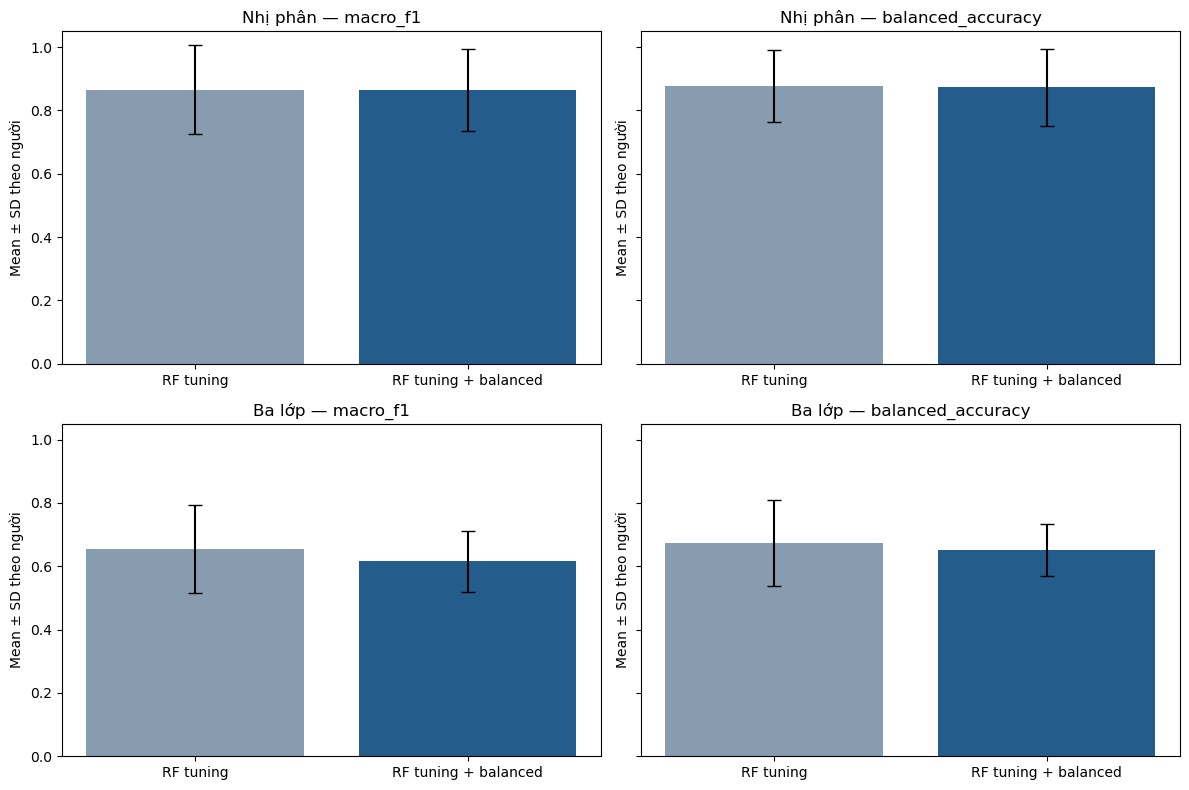

In [6]:
figures = experiment / 'figures'
figures.mkdir(exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10})
fig, axes = plt.subplots(2,2,figsize=(12,8),sharey=True)
for i,task in enumerate(tasks):
    part=summary.loc[summary.task.eq(task)].set_index('variant').loc[['plain','balanced']]
    for j,metric in enumerate(metrics):
        axes[i,j].bar(['RF tuning','RF tuning + balanced'],part[metric+'_mean'],yerr=part[metric+'_std'],capsize=5,color=['#879CAF','#245C8C'])
        axes[i,j].set_title(f'{task_names[task]} — {metric}')
        axes[i,j].set_ylim(0,1.05)
        axes[i,j].set_ylabel('Mean ± SD theo người')
fig.tight_layout();fig.savefig(figures/'rf_plain_vs_balanced.png',dpi=150,bbox_inches='tight');plt.show()


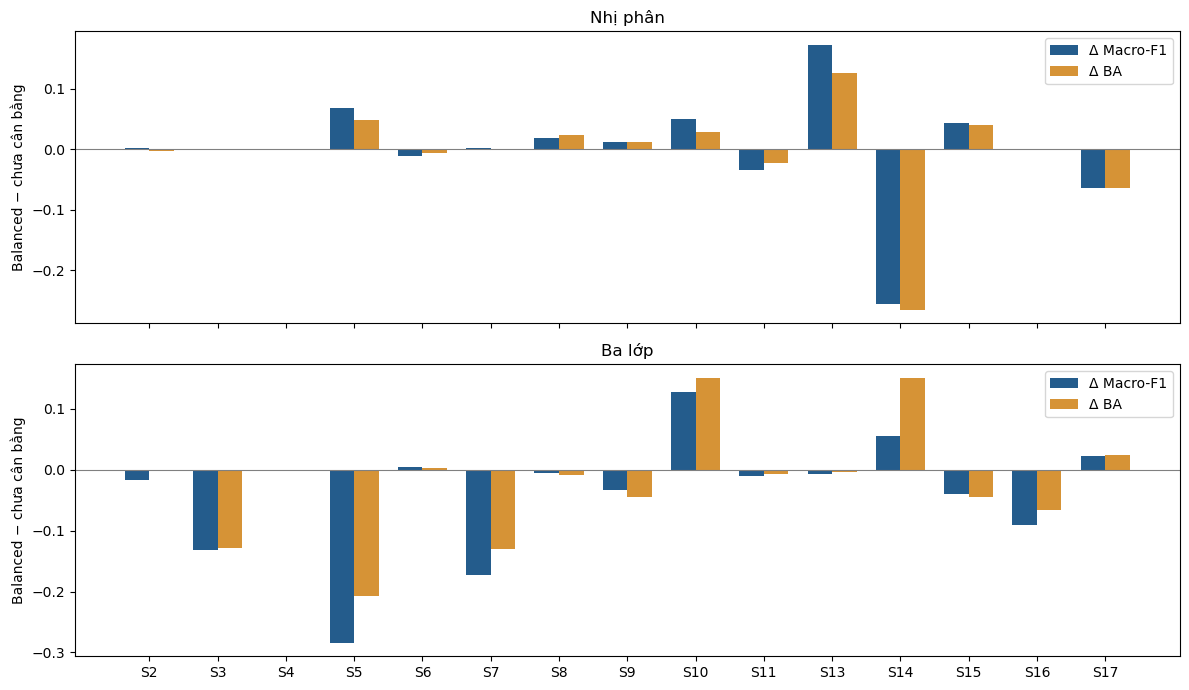

In [7]:
order=config['expected_subjects']
fig,axes=plt.subplots(2,1,figsize=(12,7),sharex=True)
for ax,task in zip(axes,tasks):
    part=comparison.loc[comparison.task.eq(task)].set_index('subject_id').loc[order]
    x=np.arange(len(order))
    ax.bar(x-.18,part.macro_f1_delta,.36,label='Δ Macro-F1',color='#245C8C')
    ax.bar(x+.18,part.balanced_accuracy_delta,.36,label='Δ BA',color='#D69336')
    ax.axhline(0,color='gray',linewidth=.8);ax.set_title(task_names[task]);ax.legend()
    ax.set_ylabel('Balanced − chưa cân bằng')
axes[-1].set_xticks(np.arange(len(order)),order)
fig.tight_layout();fig.savefig(figures/'rf_balancing_delta_by_subject.png',dpi=150,bbox_inches='tight');plt.show()


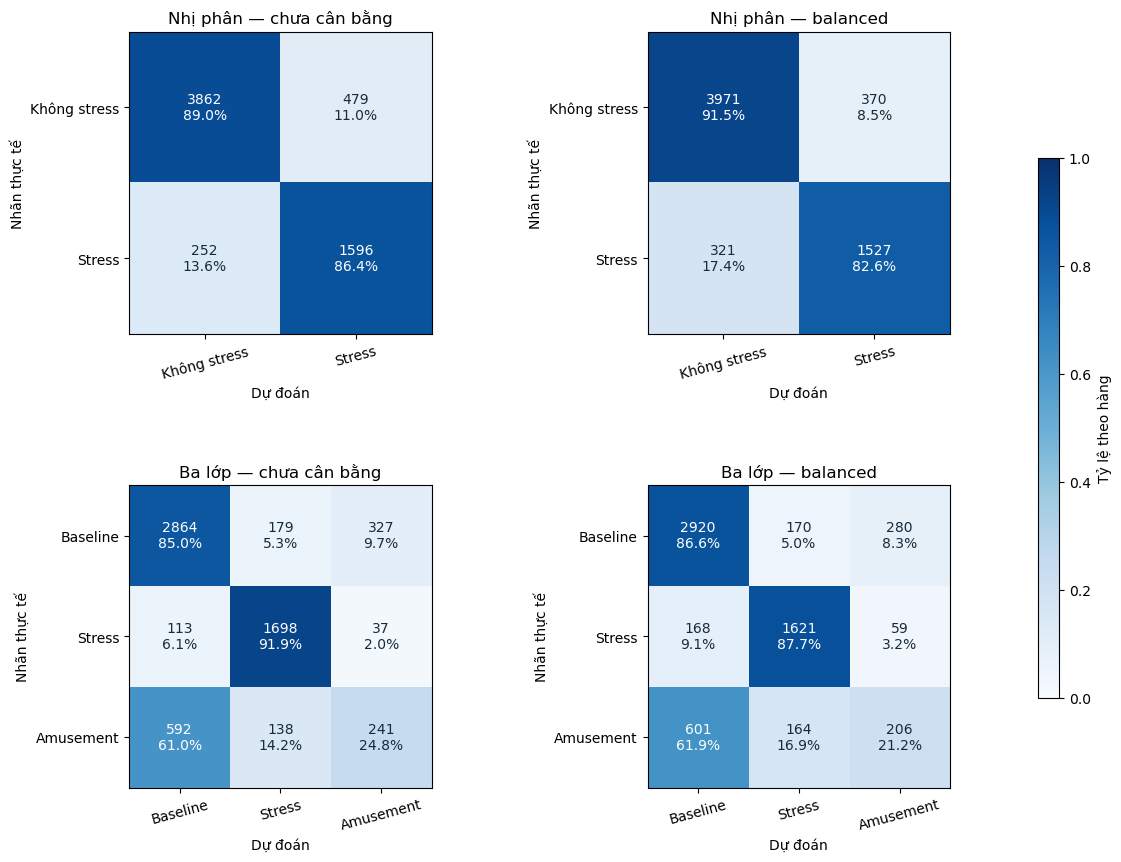

In [8]:
fig,axes=plt.subplots(2,2,figsize=(12,9))
for i,task in enumerate(tasks):
    names=['Không stress','Stress'] if task=='binary' else ['Baseline','Stress','Amusement']
    for j,variant in enumerate(['plain','balanced']):
        saved=json.loads((output/f'confusion_{task}_{variant}.json').read_text(encoding='utf-8'))
        matrix=np.asarray(saved['matrix']); normalized=matrix/matrix.sum(axis=1,keepdims=True)
        ax=axes[i,j];im=ax.imshow(normalized,cmap='Blues',vmin=0,vmax=1)
        for a in range(len(names)):
            for b in range(len(names)):
                ax.text(b,a,f'{matrix[a,b]}\n{normalized[a,b]:.1%}',ha='center',va='center',color='white' if normalized[a,b]>.55 else '#172B3A')
        ax.set_xticks(range(len(names)),names,rotation=15);ax.set_yticks(range(len(names)),names)
        ax.set_title(f"{task_names[task]} — {'chưa cân bằng' if variant=='plain' else 'balanced'}")
        ax.set_xlabel('Dự đoán');ax.set_ylabel('Nhãn thực tế')
fig.subplots_adjust(left=.12,right=.85,bottom=.10,top=.94,wspace=.45,hspace=.5)
cax=fig.add_axes([.90,.20,.018,.60]);fig.colorbar(im,cax=cax,label='Tỷ lệ theo hàng')
fig.savefig(figures/'rf_balancing_confusion_matrices.png',dpi=150,bbox_inches='tight');plt.show()


## 09 — Phân tích

Mức cải thiện được xem xét qua điểm trung bình và số người tăng hoặc giảm điểm. Recall theo lớp tính trên dự đoán OOF gộp cửa sổ, do đó có cách tính trọng số khác với mean theo người. Chênh lệch quan sát chưa đủ để kết luận ý nghĩa thống kê.


In [9]:
paragraphs=[]
for task in tasks:
    part=comparison.loc[comparison.task.eq(task)]
    wins=int(part.macro_f1_delta.gt(1e-10).sum()); losses=int(part.macro_f1_delta.lt(-1e-10).sum())
    weak=part.loc[part.macro_f1_balanced.idxmin()]
    paragraphs.append(f"### {task_names[task]}\nMacro-F1 thay đổi {part.macro_f1_delta.mean():+.4f}; Balanced Accuracy thay đổi {part.balanced_accuracy_delta.mean():+.4f}. Macro-F1 tăng ở {wins}/15 người, giảm ở {losses}/15 người. Fold có Macro-F1 cân bằng thấp nhất là {weak.subject_id} ({weak.macro_f1_balanced:.4f}).")
display(Markdown('\n\n'.join(paragraphs)))
recall_comparison=recalls.pivot(index=['task','label'],columns='variant',values='recall')
recall_comparison['delta']=recall_comparison['balanced']-recall_comparison['plain']
display(recall_comparison.round(4))


### Nhị phân
Macro-F1 thay đổi +0.0002; Balanced Accuracy thay đổi -0.0056. Macro-F1 tăng ở 8/15 người, giảm ở 4/15 người. Fold có Macro-F1 cân bằng thấp nhất là S10 (0.5493).

### Ba lớp
Macro-F1 thay đổi -0.0386; Balanced Accuracy thay đổi -0.0206. Macro-F1 tăng ở 4/15 người, giảm ở 10/15 người. Fold có Macro-F1 cân bằng thấp nhất là S13 (0.4934).

variant           balanced   plain   delta
task       label                          
binary     0        0.9148  0.8897  0.0251
           1        0.8263  0.8636 -0.0373
multiclass 1        0.8665  0.8499  0.0166
           2        0.8772  0.9188 -0.0417
           3        0.2122  0.2482 -0.0360

## 10 — Kết luận và nguồn kết quả

Xem kết quả riêng cho từng bài toán. Khi cân nhắc cân bằng lớp, xem cả điểm trung bình và mức thay đổi điểm theo người. Xem recall lớp nào tăng và lớp nào giảm. Chưa chọn mô hình triển khai hoặc huấn luyện pipeline cuối cùng trong thực nghiệm này.


In [10]:
lines=[]
for task in tasks:
    part=comparison.loc[comparison.task.eq(task)]
    delta=part.macro_f1_delta.mean()
    direction='tăng' if delta>1e-10 else 'giảm' if delta< -1e-10 else 'không đổi'
    lines.append(f'- **{task_names[task]}:** Macro-F1 trung bình {direction} ({delta:+.4f}); Balanced Accuracy thay đổi {part.balanced_accuracy_delta.mean():+.4f}.')
display(Markdown('\n'.join(lines)))
manifest=json.loads((output/'config.json').read_text(encoding='utf-8'))
print('Nguồn đối chứng:',reference)
print('Nguồn EXP-014:',output)
print('Chữ ký:',proof['signature'])
print('SHA256 dữ liệu:',proof['data_sha256'])
print('Git commit:',manifest.get('git_commit'))
display(manifest['environment'])
print('Nguồn mã huấn luyện: source_snapshot.zip; kiểm chứng: verification.json trong outputs/.')


- **Nhị phân:** Macro-F1 trung bình tăng (+0.0002); Balanced Accuracy thay đổi -0.0056.
- **Ba lớp:** Macro-F1 trung bình giảm (-0.0386); Balanced Accuracy thay đổi -0.0206.

Nguồn đối chứng: d:\mayhoc\Machine-learning\wesad-stress-detection\outputs\exp009_rf_mai_20261120
Nguồn EXP-014: d:\mayhoc\Machine-learning\wesad-stress-detection\outputs\exp014_rf_mai_20261121
Chữ ký: 5e429b2050c152dff24bd68cb2eb39fdec739d9be5f2ffa004f5ad11dbb99b90
SHA256 dữ liệu: 2f2fddd678f333a800f2869d2e78b407934b2c3492190ed70e28d8a9107fd8ba
Git commit: None


{'python': '3.12.14 (main, Sep 29 2026, 15:00:58) [MSC v.1944 64 bit (AMD64)]',
 'packages': {'numpy': '2.5.4',
  'pandas': '3.1.0',
  'PyYAML': '6.0.3',
  'scipy': '1.18.1',
  'scikit-learn': '1.9.1',
  'imbalanced-learn': '0.14.2'}}

Nguồn mã huấn luyện: source_snapshot.zip; kiểm chứng: verification.json trong outputs/.


## So sánh train và test -22/11/2026

Tính điểm theo từng người trong LOSO. Trình bày riêng nhị phân và ba lớp. Thanh sai số là SD giữa 15 fold, không phải khoảng tin cậy.

Fit lại mỗi fold với đúng cấu hình đã dùng để tính thêm điểm train. Kiểm tra dự đoán test có khớp kết quả cũ trước khi lưu. Điểm train là điểm trên dữ liệu đã học, không phải điểm validation.


train_macro_f1         test_macro_f1         gap_macro_f1  \
                              mean     std          mean     std         mean   
task       variant                                                              
binary     balanced         0.9996  0.0007        0.8657  0.1300       0.1339   
multiclass balanced         1.0000  0.0001        0.6154  0.0957       0.3846   

                            train_balanced_accuracy          \
                        std                    mean     std   
task       variant                                            
binary     balanced  0.1295                  0.9998  0.0004   
multiclass balanced  0.0957                  1.0000  0.0000   

                    test_balanced_accuracy         gap_balanced_accuracy  \
                                      mean     std                  mean   
task       variant                                                         
binary     balanced                 0.8727  0.1205                0.1271   
multiclass balanced                 0.6526  0.0817                0.3474   

                             
                        std  
task       variant           
binary     balanced  0.1202  
multiclass balanced  0.0817

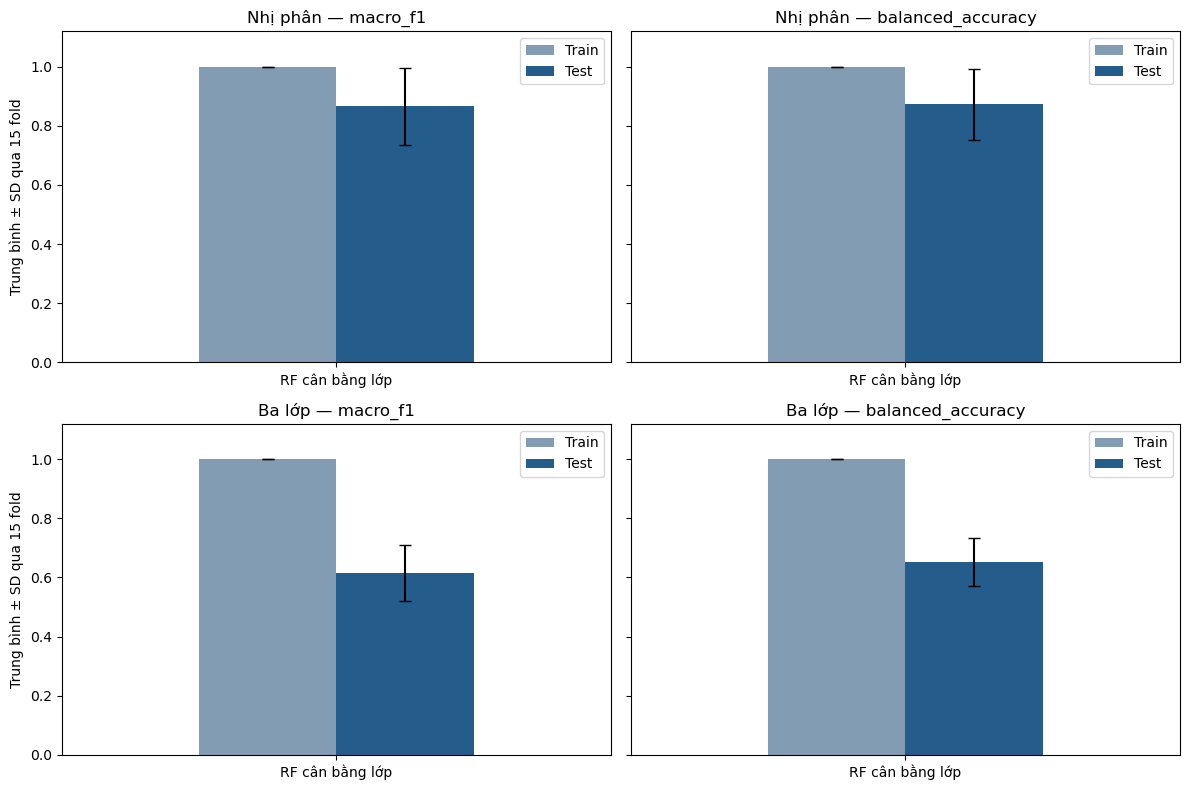

### Nhận xét train–test

- Nhị phân, RF cân bằng lớp: train Macro-F1 0.9996; test Macro-F1 0.8657; khoảng cách 0.1339. Train BA 0.9998; test BA 0.8727.

- Ba lớp, RF cân bằng lớp: train Macro-F1 1.0000; test Macro-F1 0.6154; khoảng cách 0.3846. Train BA 1.0000; test BA 0.6526.

Khoảng cách train–test mô tả mức chênh lệch giữa dữ liệu đã học và người giữ riêng. Khoảng cách lớn gợi ý cần xem xét overfitting và khác biệt giữa người; chưa đủ để xác định một nguyên nhân duy nhất. Đánh giá hiệu quả dựa trên cả điểm test và độ phân tán theo người.

In [11]:
from pathlib import Path
import json
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

RUN_TRAIN_TEST = True

here_tt = Path.cwd()
repo_tt = next(p for p in (here_tt, *here_tt.parents) if (p / 'src/wesad/evaluation.py').is_file())
package_tt = repo_tt / 'experiments/03_balancing/EXP-014_RF'
source_tt = repo_tt / 'outputs/exp014_rf_mai_20261121'

if RUN_TRAIN_TEST:
    subprocess.run([
        str(repo_tt / '.venv-g1/Scripts/python.exe'), '-X', 'utf8',
        str(repo_tt / 'scripts/measure_rf_train_test.py'),
        '--source', str(source_tt), '--destination', str(package_tt),
    ], cwd=repo_tt, check=True)
    proof_tt = json.loads((package_tt / 'train_test_verification.json').read_text(encoding='utf-8'))
    assert proof_tt['status'] == 'passed' and proof_tt['n_folds'] == 30
    assert proof_tt['matched_test_predictions'] == 12378
    scores_tt = pd.read_csv(package_tt / 'train_test_metrics.csv')
    assert len(scores_tt) == 30
    assert not scores_tt.duplicated(['task', 'subject_id', 'variant']).any()
    assert set(scores_tt.task) == {'binary', 'multiclass'}
    assert all(len(g) == 15 and g.subject_id.nunique() == 15
               for _, g in scores_tt.groupby(['task', 'variant']))
    for metric in ['macro_f1', 'balanced_accuracy']:
        scores_tt[f'gap_{metric}'] = scores_tt[f'train_{metric}'] - scores_tt[f'test_{metric}']
    columns_tt = [f'{split}_{metric}' for metric in ['macro_f1', 'balanced_accuracy']
                  for split in ['train', 'test', 'gap']]
    assert scores_tt[columns_tt].notna().all().all()
    assert scores_tt[[c for c in columns_tt if not c.startswith('gap_')]].apply(
        lambda col: col.between(0, 1).all()).all()
    summary_tt = scores_tt.groupby(['task', 'variant'])[columns_tt].agg(['mean', 'std'])
    display(summary_tt.round(4))
    summary_tt.to_csv(package_tt / 'train_test_summary.csv')

    names_tt = {'binary': 'Nhị phân', 'multiclass': 'Ba lớp'}
    labels_tt = {'baseline': 'RF mặc định', 'balanced': 'RF cân bằng lớp',
                 'full68': 'Đủ 68 đặc trưng', 'selected': 'Chọn đặc trưng'}
    fig_tt, axes_tt = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
    for row, task in enumerate(['binary', 'multiclass']):
        part_tt = scores_tt.loc[scores_tt.task.eq(task)]
        for col, metric in enumerate(['macro_f1', 'balanced_accuracy']):
            fields_tt = [f'train_{metric}', f'test_{metric}']
            means_tt = part_tt.groupby('variant')[fields_tt].mean()
            errors_tt = part_tt.groupby('variant')[fields_tt].std(ddof=1)
            means_tt = means_tt.rename(index=labels_tt, columns={fields_tt[0]: 'Train', fields_tt[1]: 'Test'})
            errors_tt = errors_tt.rename(index=labels_tt, columns={fields_tt[0]: 'Train', fields_tt[1]: 'Test'})
            means_tt.plot.bar(yerr=errors_tt, ax=axes_tt[row, col], rot=0, capsize=4,
                              color=['#829CB3', '#245C8C'])
            axes_tt[row, col].set_title(f'{names_tt[task]} — {metric}')
            axes_tt[row, col].set_ylim(0, 1.12)
            axes_tt[row, col].set_xlabel('')
            axes_tt[row, col].set_ylabel('Trung bình ± SD qua 15 fold')
    fig_tt.tight_layout()
    (package_tt / 'figures').mkdir(exist_ok=True)
    fig_tt.savefig(package_tt / 'figures/train_vs_test.png', dpi=150, bbox_inches='tight')
    plt.show()

    notes_tt = ['### Nhận xét train–test']
    for (task, variant), group_tt in scores_tt.groupby(['task', 'variant']):
        notes_tt.append(
            f'- {names_tt[task]}, {labels_tt[variant]}: train Macro-F1 '
            f'{group_tt.train_macro_f1.mean():.4f}; test Macro-F1 '
            f'{group_tt.test_macro_f1.mean():.4f}; khoảng cách '
            f'{group_tt.gap_macro_f1.mean():.4f}. Train BA '
            f'{group_tt.train_balanced_accuracy.mean():.4f}; test BA '
            f'{group_tt.test_balanced_accuracy.mean():.4f}.'
        )
    notes_tt.append('Khoảng cách train–test mô tả mức chênh lệch giữa dữ liệu đã học và người giữ riêng. '
                    'Khoảng cách lớn gợi ý cần xem xét overfitting và khác biệt giữa người; '
                    'chưa đủ để xác định một nguyên nhân duy nhất. '
                    'Đánh giá hiệu quả dựa trên cả điểm test và độ phân tán theo người.')
    display(Markdown('\n\n'.join(notes_tt)))
